Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MAE: 238.74
R² Score: 0.18


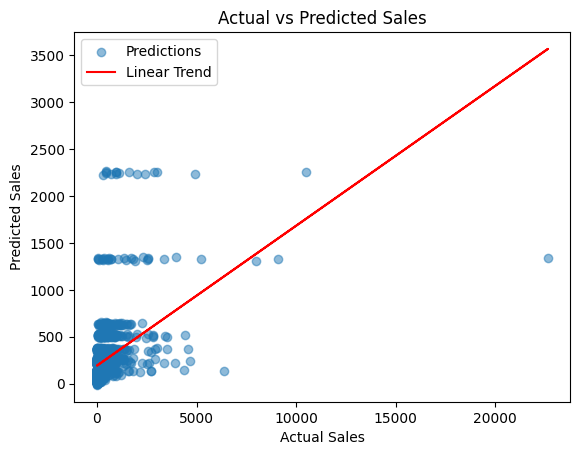

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Mount Google Drive
drive.mount('/content/drive')

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/PBA PRACTICAL FILE/superstore.csv')

# Features and target
X = df[['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category']]
y = df['Sales']

# Convert categorical data into numbers
X = pd.get_dummies(X, drop_first=True)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
pred = model.predict(X_test)

# Evaluation
print("MAE:", round(mean_absolute_error(y_test, pred), 2))
print("R² Score:", round(r2_score(y_test, pred), 2))

# Actual vs Predicted graph
plt.scatter(y_test, pred, alpha=0.5, label='Predictions')

# Linear trend line
m, b = __import__('numpy').polyfit(y_test, pred, 1)
plt.plot(y_test, m * y_test + b, color='red', label='Linear Trend')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.legend()
plt.show()